**Name:** Akhilesh Kombe                       
**Division:** A &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; **Batch:** A3    
**PRN:** 202401040244                         
**Roll No.:** TY-057                                     


# Practical No. 02 : Problem Solving through Search


### Question 1: BFS vs DFS in a Maze

You are in a maze. Which algorithm would you use?

**a) BFS:** If you want the shortest path from entrance to exit.

**b) DFS:** If you want to explore one path completely before trying another.

### Question 2: Implementation of A* (A-Star) Search Algorithm

A robot has to move from its current position to a destination while avoiding obstacles. It should find an efficient/shortest path.

**Hint:** Assume a graph/grid of different paths with cost and heuristic distance.

# Question 1: BFS vs DFS in a Maze

## Answer

The choice of algorithm depends on the objective.

### a) BFS (Breadth-First Search)

If I want to find the **shortest path from the entrance to the exit**, I would use **BFS**.

BFS explores the maze **level by level**. Therefore, in an unweighted maze where every movement has the same cost, BFS finds the shortest path.

**Data Structure Used:** Queue

### b) DFS (Depth-First Search)

If I want to **explore one path completely before trying another path**, I would use **DFS**.

DFS continues along one path as deeply as possible. If it reaches a dead end, it backtracks and tries another path.

**Data Structure Used:** Stack

| Requirement | Algorithm |
|---|---|
| Find shortest path from entrance to exit | BFS |
| Explore one path completely before another | DFS |
| Level-by-level exploration | BFS |
| Deep exploration and backtracking | DFS |
| Data Structure | BFS → Queue |
| Data Structure | DFS → Stack |

## Final Choice

**Shortest Path → BFS**

**Explore One Path Completely → DFS**

**a) BFS Code**

In [ ]:
from collections import deque

# Simple graph representing a maze
maze = {
    'A': ['B', 'C'],
    'B': ['D'],
    'C': ['E'],
    'D': ['F'],
    'E': ['F'],
    'F': []
}

def bfs(start, goal):
    queue = deque([[start]])
    visited = set()

    while queue:
        path = queue.popleft()
        node = path[-1]

        if node == goal:
            return path

        if node not in visited:
            visited.add(node)

            for neighbour in maze[node]:
                new_path = path + [neighbour]
                queue.append(new_path)

    return None


bfs_path = bfs('A', 'F')

print("BFS Shortest Path:")
print(" -> ".join(bfs_path))

BFS Shortest Path:
A -> B -> D -> F


**b) DFS**

In [ ]:
# DFS using Stack

def dfs(start, goal):
    stack = [[start]]
    visited = set()

    while stack:
        path = stack.pop()
        node = path[-1]

        if node == goal:
            return path

        if node not in visited:
            visited.add(node)

            for neighbour in maze[node]:
                new_path = path + [neighbour]
                stack.append(new_path)

    return None


dfs_path = dfs('A', 'F')

print("DFS Path:")
print(" -> ".join(dfs_path))

DFS Path:
A -> C -> E -> F


# BFS/DFS Explanation
## Explanation

### BFS

BFS explores all the nodes at the current level before moving to the next level.

Therefore, when all movements have equal cost, BFS guarantees the shortest path in terms of the number of steps.

BFS uses a **Queue (FIFO)** data structure.

### DFS

DFS selects one path and continues exploring it until it reaches the destination or a dead end.

If a dead end is reached, DFS backtracks and tries another path.

DFS uses a **Stack (LIFO)** data structure.

## Final Answer

If I am in a maze:

- For the **shortest path from entrance to exit → BFS**
- For **exploring one path completely before trying another → DFS**

# Question 2: Implementation of A* (A-Star) Search Algorithm

## Problem Statement

A robot needs to move from a starting position to a destination in a grid environment.

The grid contains obstacles that the robot cannot pass through.

The objective is to implement the **A* (A-Star) Search Algorithm** to find an efficient and shortest path from the starting position to the destination while avoiding obstacles.

## Aim

To implement the **A* Search Algorithm** to find an efficient and shortest path for a robot from its current position to a destination while avoiding obstacles.

## Theory

A* (A-Star) is an **informed search algorithm** used to find the shortest or most efficient path between a starting node and a destination node.

A* combines ideas from:

- Uniform Cost Search
- Greedy Best-First Search

The evaluation function used by A* is:

### f(n) = g(n) + h(n)

Where:

- **g(n)** = Actual cost from the starting node to node n.
- **h(n)** = Estimated cost from node n to the destination.
- **f(n)** = Total estimated cost of the path through node n.

For this problem, the robot can move:

- Up
- Down
- Left
- Right

Therefore, **Manhattan Distance** is used as the heuristic.

### Manhattan Distance

**h(n) = |x1 - x2| + |y1 - y2|**

A* selects the node having the smallest f(n) value and continues searching until the destination is reached.

With an admissible heuristic such as Manhattan distance in this grid, A* can find an optimal shortest path.

## Algorithm: A* Search

**Input:** Grid, starting position, destination position and obstacles.

**Output:** Shortest path from the starting position to the destination.

### Steps

1. Start the algorithm.
2. Define the grid containing free cells and obstacles.
3. Define the starting position and destination.
4. Initialize a priority queue with the starting node.
5. Set `g(start) = 0`.
6. Calculate the Manhattan Distance heuristic.
7. Calculate:

   **f(n) = g(n) + h(n)**

8. Select the node having the smallest `f(n)` value.
9. If the selected node is the destination, stop searching.
10. Find all valid neighboring cells.
11. Ignore cells outside the grid.
12. Ignore obstacle cells.
13. Calculate the new cost for every valid neighbor.
14. If a better path is found, update its cost and parent.
15. Add the node to the priority queue.
16. Repeat until the destination is found or no nodes remain.
17. Trace parent nodes backward to reconstruct the path.
18. Reverse the path to obtain the route from start to destination.
19. Display the final path and path cost.
20. Stop.

## Grid Representation

The environment is represented using a **6 × 6 grid**.

- `0` represents a free cell.
- `1` represents an obstacle.
- `S` represents the starting position.
- `G` represents the destination.

**Starting Position:** `(0, 0)`

**Destination Position:** `(5, 5)`

The robot can move only **Up, Down, Left or Right**.

# Main A* Code

In [ ]:
import heapq

# -----------------------------------------
# A* Algorithm for Robot Path Finding
# -----------------------------------------

# Grid:
# 0 = Free cell
# 1 = Obstacle

grid = [
    [0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0, 0],
    [0, 0, 0, 1, 0, 0],
    [0, 1, 0, 0, 0, 0],
    [0, 1, 0, 1, 1, 0],
    [0, 0, 0, 0, 0, 0]
]

# Starting position
start = (0, 0)

# Destination position
goal = (5, 5)


# -----------------------------------------
# Heuristic Function
# -----------------------------------------

def heuristic(node, goal):
    """Calculate Manhattan Distance."""
    return abs(node[0] - goal[0]) + abs(node[1] - goal[1])


# -----------------------------------------
# A* Algorithm
# -----------------------------------------

def a_star(grid, start, goal):

    rows = len(grid)
    cols = len(grid[0])

    # Priority Queue
    open_list = []

    # f-cost, node
    heapq.heappush(
        open_list,
        (heuristic(start, goal), start)
    )

    # Stores previous node
    came_from = {}

    # Actual cost from start
    g_cost = {start: 0}

    # Closed set for already processed nodes
    closed = set()

    # Possible robot movements
    directions = [
        (-1, 0),  # Up
        (1, 0),   # Down
        (0, -1),  # Left
        (0, 1)    # Right
    ]

    while open_list:

        # Get node having minimum f(n)
        current_f, current = heapq.heappop(open_list)

        # Skip already processed node
        if current in closed:
            continue

        # Goal reached
        if current == goal:

            path = []

            # Reconstruct path
            while current in came_from:
                path.append(current)
                current = came_from[current]

            path.append(start)

            # Reverse path
            path.reverse()

            return path

        closed.add(current)

        # Explore neighboring cells
        for dr, dc in directions:

            neighbor = (
                current[0] + dr,
                current[1] + dc
            )

            # Check grid boundaries
            if not (
                0 <= neighbor[0] < rows and
                0 <= neighbor[1] < cols
            ):
                continue

            # Ignore obstacles
            if grid[neighbor[0]][neighbor[1]] == 1:
                continue

            # Ignore processed nodes
            if neighbor in closed:
                continue

            # Calculate new g(n)
            new_g = g_cost[current] + 1

            # Check whether better path is found
            if (
                neighbor not in g_cost
                or new_g < g_cost[neighbor]
            ):

                g_cost[neighbor] = new_g

                # h(n)
                h_cost = heuristic(neighbor, goal)

                # f(n) = g(n) + h(n)
                f_cost = new_g + h_cost

                # Add node to priority queue
                heapq.heappush(
                    open_list,
                    (f_cost, neighbor)
                )

                # Store parent
                came_from[neighbor] = current

    return None


# -----------------------------------------
# Execute A*
# -----------------------------------------

path = a_star(grid, start, goal)


# -----------------------------------------
# Display Result
# -----------------------------------------

if path:

    print("Shortest Path Found:")

    for position in path:
        print(position)

    print("\nPath Cost:")
    print(len(path) - 1)

else:
    print("No path found!")

Shortest Path Found:
(0, 0)
(0, 1)
(0, 2)
(0, 3)
(0, 4)
(0, 5)
(1, 5)
(2, 5)
(3, 5)
(4, 5)
(5, 5)

Path Cost:
10


**Visualize the Robot Path**

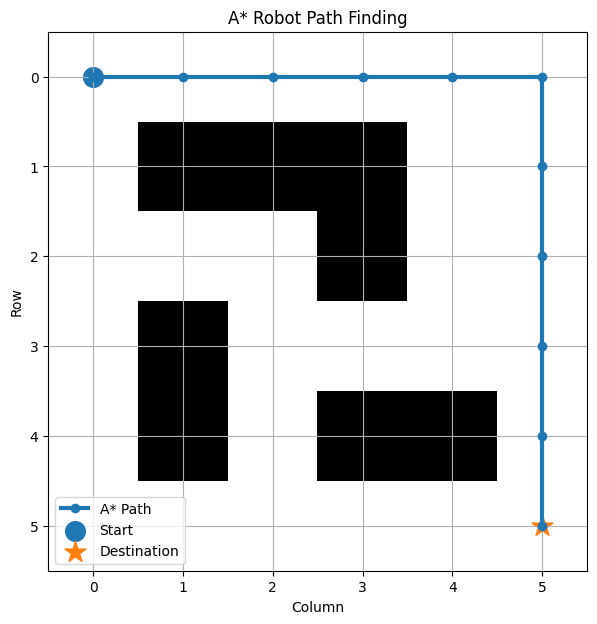

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

# Show grid
plt.imshow(grid, cmap="gray_r")

# Show A* path
if path:

    x = [position[1] for position in path]
    y = [position[0] for position in path]

    plt.plot(
        x,
        y,
        marker="o",
        linewidth=3,
        label="A* Path"
    )

# Starting position
plt.scatter(
    start[1],
    start[0],
    s=200,
    marker="o",
    label="Start"
)

# Destination
plt.scatter(
    goal[1],
    goal[0],
    s=250,
    marker="*",
    label="Destination"
)

plt.title("A* Robot Path Finding")
plt.xlabel("Column")
plt.ylabel("Row")

plt.xticks(range(len(grid[0])))
plt.yticks(range(len(grid)))

plt.grid(True)
plt.legend()

plt.show()

## Working of A* Algorithm

The A* algorithm starts from the initial position `(0, 0)`.

For every possible movement, it calculates:

### f(n) = g(n) + h(n)

The algorithm considers both:

- The actual distance already travelled.
- The estimated distance remaining to the destination.

It avoids cells containing obstacles and explores the most promising cells first.

When the destination `(5, 5)` is reached, the algorithm traces the parent nodes to obtain the final path.

Thus, A* finds an efficient shortest path while avoiding obstacles.

## Advantages of A* Algorithm

1. A* can find the shortest path when an appropriate admissible heuristic is used.
2. It uses heuristic information to guide the search efficiently.
3. It can efficiently handle pathfinding problems.
4. It can avoid obstacles while searching for a destination.
5. It is widely used in robotics, games, navigation systems and artificial intelligence.

## Applications of A*

A* Search is commonly used in:

- Robot Navigation
- GPS and Route Planning
- Video Games
- Autonomous Vehicles
- Maze Solving
- Pathfinding Systems
- Artificial Intelligence
- Network Routing

## Result

The A* (A-Star) Search Algorithm was successfully implemented in Python.

The algorithm successfully found an efficient shortest path from the starting position `(0, 0)` to the destination `(5, 5)` while avoiding obstacles.

The Manhattan Distance heuristic was used to guide the search efficiently.

The total path cost obtained was **10 movements**.

Therefore, A* is an effective algorithm for robot pathfinding and obstacle avoidance.

## Conclusion

A* is an informed search algorithm that combines the actual path cost and the estimated distance to the destination.

It uses:

### f(n) = g(n) + h(n)

where:

- `g(n)` represents the actual cost from the start.
- `h(n)` represents the estimated cost to the destination.

By using these values, the algorithm selects promising paths and avoids unnecessary exploration.

In this experiment, A* successfully guided the robot from the starting point to the destination while avoiding obstacles and finding a shortest path.




.
